In [6]:
# global imports + seeds so every code block below runs in one kernel.
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
from itertools import product

np.random.seed(42)
torch.manual_seed(42)

Iter   0: m=1.776, c=0.270, loss=235.955
Iter  20: m=2.584, c=0.451, loss=0.304
Iter  40: m=2.577, c=0.504, loss=0.290
Iter  60: m=2.569, c=0.551, loss=0.278
Iter  80: m=2.563, c=0.594, loss=0.269
Iter 100: m=2.557, c=0.633, loss=0.261
Iter 120: m=2.552, c=0.669, loss=0.254
Iter 140: m=2.547, c=0.701, loss=0.249
Iter 160: m=2.543, c=0.730, loss=0.245
Iter 180: m=2.539, c=0.756, loss=0.241


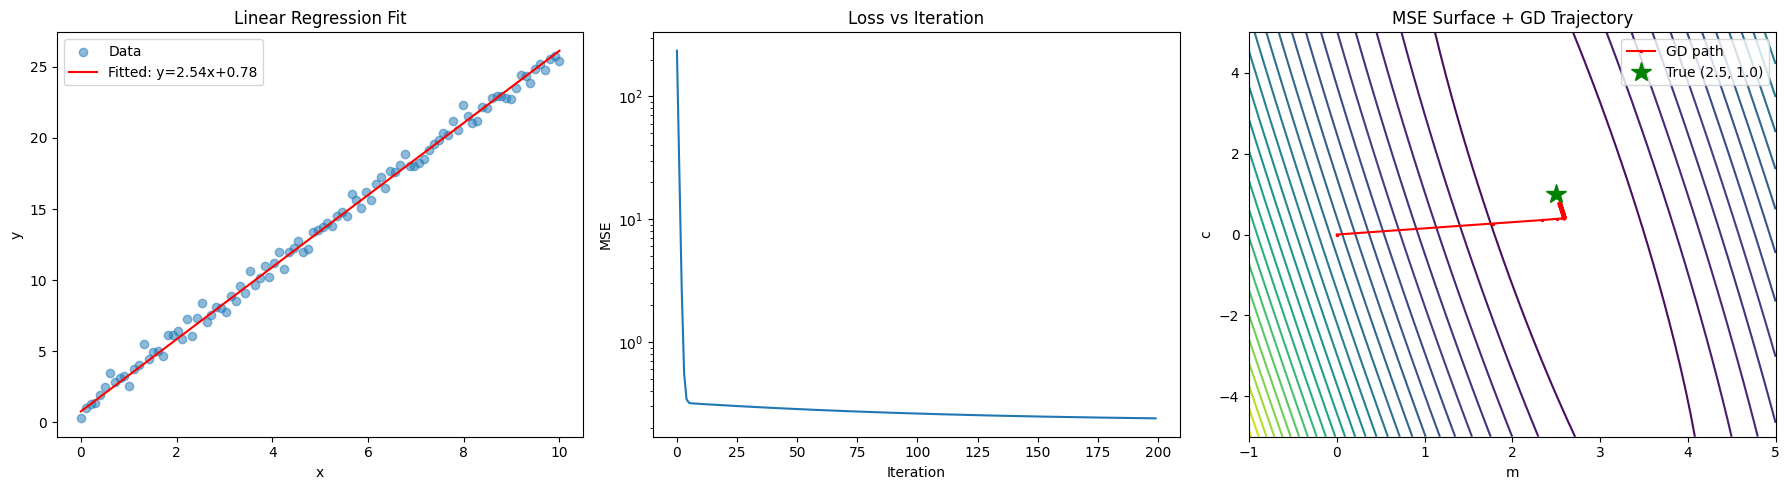

In [10]:
# SECTION 2.1: Gradient Descent on Linear Regression (from scratch).
# WHAT: Fit y = mx + c by iteratively minimizing MSE.
# HOW:  Compute ∂L/∂m and ∂L/∂c each iteration; update opposite to gradient.
# WHY:  Foundation for all neural network training.

# ---- Synthetic data: y = 2.5x + 1 + noise ----
X = np.linspace(0, 10, 100).astype(np.float32)              # 100 points, float32 for later torch use
y = 2.5 * X + 1.0 + np.random.randn(100).astype(np.float32) * 0.5  # ground truth + Gaussian noise

# ---- Initialize parameters ----
m, c = 0.0, 0.0                                             # slope and intercept start at zero
learning_rate = 0.01                                        # step size α
losses = []                                                 # track loss per iteration
m_history, c_history = [], []                               # track parameters for contour plot

# ---- Training loop ----
for i in range(200):                                        # 200 full-batch passes
    y_pred = m * X + c                                      # forward pass
    error  = y_pred - y                                     # residuals (ŷ - y)
    loss   = np.mean(error ** 2)                            # MSE
    losses.append(loss)                                     # log loss
    m_history.append(m); c_history.append(c)                # log params

    # ---- Gradients of MSE ----
    dm = (2 / len(X)) * np.sum(error * X)                   # ∂L/∂m
    dc = (2 / len(X)) * np.sum(error)                       # ∂L/∂c

    # ---- Update ----
    m -= learning_rate * dm                                 # m ← m - α·∂L/∂m
    c -= learning_rate * dc                                 # c ← c - α·∂L/∂c

    if i % 20 == 0:                                         # log every 20 iters
        print(f"Iter {i:3d}: m={m:.3f}, c={c:.3f}, loss={loss:.3f}")

# ---- PLOT 1: Data fit + Loss curve + Parameter trajectory ----
fig, axes = plt.subplots(1, 3, figsize=(18, 5))             # three panels

axes[0].scatter(X, y, alpha=0.5, label='Data')              # raw points
axes[0].plot(X, m * X + c, 'r-', label=f'Fitted: y={m:.2f}x+{c:.2f}')
axes[0].legend(); axes[0].set_title('Linear Regression Fit')
axes[0].set_xlabel('x'); axes[0].set_ylabel('y')

axes[1].plot(losses)                                        # loss curve
axes[1].set_title('Loss vs Iteration'); axes[1].set_xlabel('Iteration')
axes[1].set_ylabel('MSE'); axes[1].set_yscale('log')        # log scale shows convergence rate

# Contour of MSE surface with GD trajectory
m_grid = np.linspace(-1, 5, 100)                            # m axis
c_grid = np.linspace(-5, 5, 100)                            # c axis
M, C = np.meshgrid(m_grid, c_grid)                          # 2D grid
Z = np.zeros_like(M)                                        # MSE surface
for i in range(M.shape[0]):
    for j in range(M.shape[1]):
        Z[i, j] = np.mean((M[i, j] * X + C[i, j] - y) ** 2) # MSE at each (m,c)
axes[2].contour(M, C, Z, levels=30, cmap='viridis')         # contours
axes[2].plot(m_history, c_history, 'r.-', markersize=3, label='GD path')
axes[2].plot(2.5, 1.0, 'g*', markersize=15, label='True (2.5, 1.0)')
axes[2].set_xlabel('m'); axes[2].set_ylabel('c')
axes[2].set_title('MSE Surface + GD Trajectory'); axes[2].legend()

plt.tight_layout(); plt.show()

Alternatives

In [13]:
# ADDED: `model` is referenced above but defined here first.

X_t = torch.tensor(X).reshape(-1, 1)                        # (100, 1)
y_t = torch.tensor(y).reshape(-1, 1)                        # (100, 1)
model = nn.Linear(1, 1)                                     # ADDED: define before use

In [14]:
# WHY: Adam often converges faster than vanilla GD on real data.
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)   # adaptive per-param LR

# WHY: SGD+momentum smooths updates and escapes shallow local minima.
optimizer = torch.optim.SGD(model.parameters(), lr=0.01, momentum=0.9)

# WHY: RMSProp adapts LR per parameter; good for non-stationary objectives.
optimizer = torch.optim.RMSprop(model.parameters(), lr=0.001)

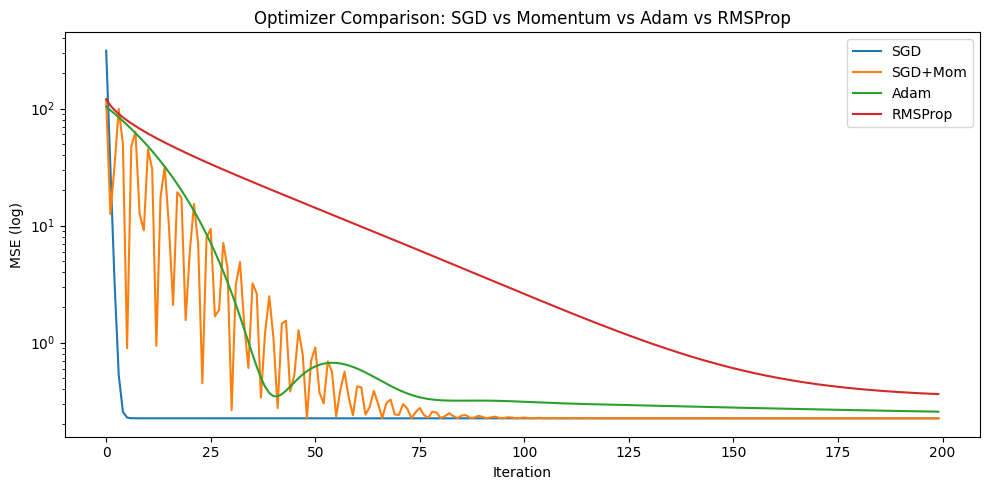

In [15]:
# PLOT: Optimizer comparison on the same linear regression task
# WHY: See how different optimizers traverse the MSE surface.
import torch                                                # torch optimizers
import torch.nn as nn                                       # layers

X_t = torch.tensor(X).reshape(-1, 1)                        # (100, 1)
y_t = torch.tensor(y).reshape(-1, 1)                        # (100, 1)

fig, ax = plt.subplots(figsize=(10, 5))                     # single panel
for name, opt_cls, lr in [
    ('SGD',     torch.optim.SGD,     0.01),
    ('SGD+Mom', torch.optim.SGD,     0.01),                 # momentum set below
    ('Adam',    torch.optim.Adam,    0.05),
    ('RMSProp', torch.optim.RMSprop, 0.01),
]:
    model = nn.Linear(1, 1)                                 # fresh model
    if name == 'SGD+Mom':
        opt = opt_cls(model.parameters(), lr=lr, momentum=0.9)
    else:
        opt = opt_cls(model.parameters(), lr=lr)
    losses_opt = []
    for i in range(200):
        opt.zero_grad()                                     # reset grads
        loss = nn.MSELoss()(model(X_t), y_t)                # MSE
        loss.backward()                                     # backprop
        opt.step()                                          # update
        losses_opt.append(loss.item())                      # log
    ax.plot(losses_opt, label=name)                         # one curve per optimizer

ax.set_yscale('log'); ax.set_xlabel('Iteration'); ax.set_ylabel('MSE (log)')
ax.set_title('Optimizer Comparison: SGD vs Momentum vs Adam vs RMSProp')
ax.legend(); plt.tight_layout(); plt.show()

In [16]:
# ---- WRONG: missing gradient computation ----
m, c = 0.0, 0.0
for i in range(200):
    y_pred = m * X + c
    loss = np.mean((y_pred - y) ** 2)
    # no gradient computed, no update
print(f"[WRONG] m={m:.3f}, c={c:.3f}")                       # stays at 0, 0

# ---- RIGHT: with gradient + update ----
m, c = 0.0, 0.0
for i in range(200):
    y_pred = m * X + c
    error = y_pred - y
    dm = (2 / len(X)) * np.sum(error * X)
    dc = (2 / len(X)) * np.sum(error)
    m -= 0.01 * dm
    c -= 0.01 * dc
print(f"[RIGHT] m={m:.3f}, c={c:.3f}")                       # converges to ~2.5, ~1.0

[WRONG] m=0.000, c=0.000
[RIGHT] m=2.535, c=0.778


/tmp/ipykernel_2690/2973612909.py:14: RuntimeWarning: overflow encountered in square
  losses_bad.append(np.mean(error ** 2))
/usr/local/lib/python3.13/dist-packages/numpy/_core/_methods.py:136: RuntimeWarning: overflow encountered in reduce
  ret = umr_sum(arr, axis, dtype, out, keepdims, where=where)
/tmp/ipykernel_2690/2973612909.py:11: RuntimeWarning: overflow encountered in multiply
  dm = (2 / len(X)) * np.sum(error * X)
/usr/local/lib/python3.13/dist-packages/numpy/_core/fromnumeric.py:86: RuntimeWarning: overflow encountered in reduce
  return ufunc.reduce(obj, axis, dtype, out, **passkwargs)
/tmp/ipykernel_2690/2973612909.py:9: RuntimeWarning: invalid value encountered in multiply
  y_pred = m * X + c


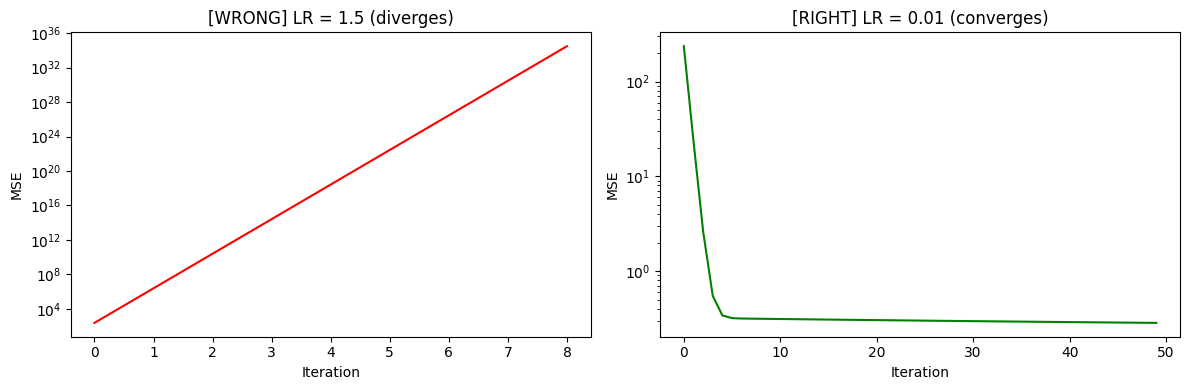

[WRONG] final loss = nan
[RIGHT] final loss = 0.2843


In [17]:
# ---- WRONG vs RIGHT: learning rate too large ----
# PLOT: Divergence vs Stable convergence
fig, ax = plt.subplots(1, 2, figsize=(12, 4))                # two panels

# WRONG: α = 1.5 → divergence
m, c = 0.0, 0.0
losses_bad = []
for i in range(50):
    y_pred = m * X + c
    error = y_pred - y
    dm = (2 / len(X)) * np.sum(error * X)
    dc = (2 / len(X)) * np.sum(error)
    m -= 1.5 * dm; c -= 1.5 * dc                             # huge LR
    losses_bad.append(np.mean(error ** 2))
ax[0].plot(losses_bad, color='red')                          # explodes
ax[0].set_title('[WRONG] LR = 1.5 (diverges)'); ax[0].set_yscale('log')
ax[0].set_xlabel('Iteration'); ax[0].set_ylabel('MSE')

# RIGHT: α = 0.01 → stable
m, c = 0.0, 0.0
losses_good = []
for i in range(50):
    y_pred = m * X + c
    error = y_pred - y
    dm = (2 / len(X)) * np.sum(error * X)
    dc = (2 / len(X)) * np.sum(error)
    m -= 0.01 * dm; c -= 0.01 * dc                           # stable LR
    losses_good.append(np.mean(error ** 2))
ax[1].plot(losses_good, color='green')                       # converges
ax[1].set_title('[RIGHT] LR = 0.01 (converges)'); ax[1].set_yscale('log')
ax[1].set_xlabel('Iteration'); ax[1].set_ylabel('MSE')

plt.tight_layout(); plt.show()
print(f"[WRONG] final loss = {losses_bad[-1]:.3e}")          # huge / NaN
print(f"[RIGHT] final loss = {losses_good[-1]:.4f}")         # small

/tmp/ipykernel_2690/181618676.py:13: RuntimeWarning: overflow encountered in square
  losses_lr.append(np.mean(error ** 2))
/tmp/ipykernel_2690/181618676.py:8: RuntimeWarning: invalid value encountered in multiply
  y_pred = m * X + c


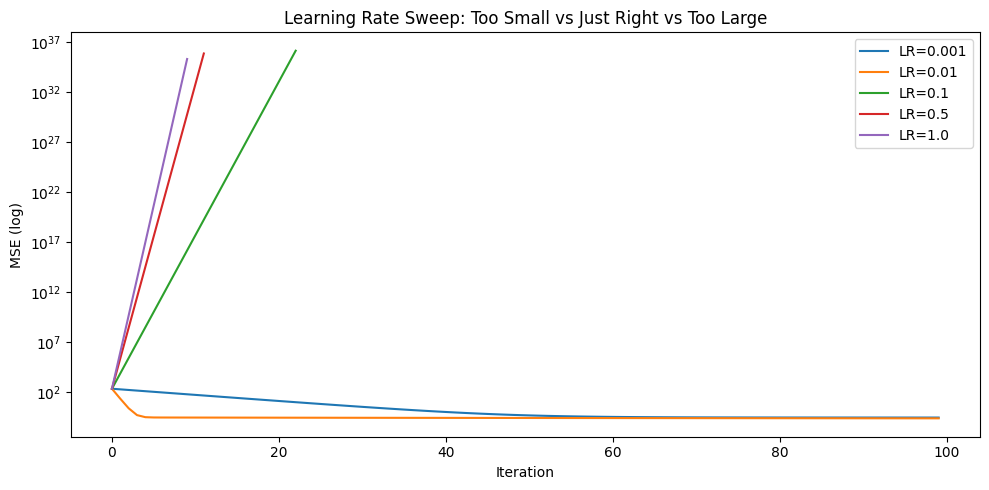

In [18]:
# ---- WRONG vs RIGHT: learning rate sweep (find the sweet spot) ----
# PLOT: Loss curves for α ∈ {0.001, 0.01, 0.1, 0.5, 1.0}
fig, ax = plt.subplots(figsize=(10, 5))                      # single panel
for lr in [0.001, 0.01, 0.1, 0.5, 1.0]:                      # sweep
    m, c = 0.0, 0.0
    losses_lr = []
    for i in range(100):
        y_pred = m * X + c
        error = y_pred - y
        dm = (2 / len(X)) * np.sum(error * X)
        dc = (2 / len(X)) * np.sum(error)
        m -= lr * dm; c -= lr * dc
        losses_lr.append(np.mean(error ** 2))
    ax.plot(losses_lr, label=f'LR={lr}')                     # one curve per LR
ax.set_yscale('log'); ax.set_xlabel('Iteration'); ax.set_ylabel('MSE (log)')
ax.set_title('Learning Rate Sweep: Too Small vs Just Right vs Too Large')
ax.legend(); plt.tight_layout(); plt.show()

Errors

In [19]:
# ---- WRONG: dtype mismatch (int64 X vs float32 weights) ----
try:
    X_int = np.arange(0, 100, dtype=np.int64)
    m = np.float32(0.0)
    y_pred = m * X_int                                       # silent upcast, but slow / inconsistent
    print(f"[WRONG] dtype={y_pred.dtype}")
except Exception as e:
    print(f"[WRONG] {e}")

# ---- RIGHT: explicit float32 cast ----
X_f = np.arange(0, 100, dtype=np.float32)                    # cast before mixing
m = np.float32(0.0)
y_pred = m * X_f
print(f"[RIGHT] dtype={y_pred.dtype}")

[WRONG] dtype=float64
[RIGHT] dtype=float32


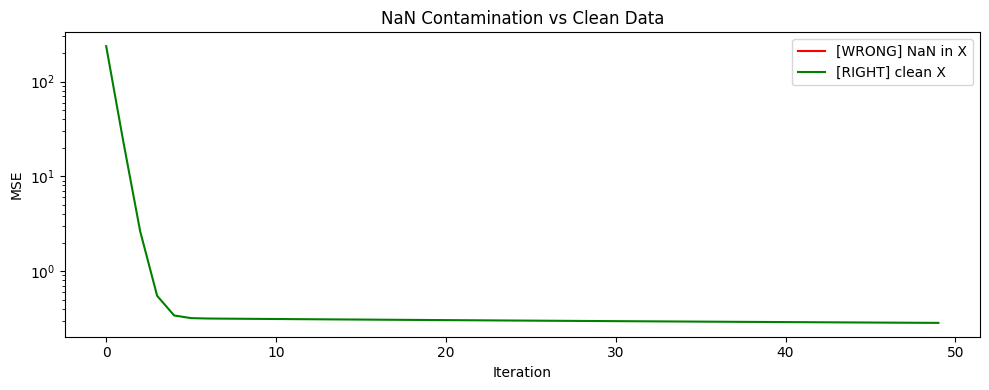

[WRONG] final loss = nan
[RIGHT] final loss = 0.2843


In [20]:
# ---- WRONG vs RIGHT: NaN loss detection ----
# PLOT: NaN loss curve vs finite loss curve
fig, ax = plt.subplots(figsize=(10, 4))                      # single panel

# WRONG: inject NaN into data
X_nan = X.copy().astype(np.float32)
X_nan[0] = np.nan                                            # corrupt one sample
m, c = 0.0, 0.0
losses_nan = []
for i in range(50):
    y_pred = m * X_nan + c
    error = y_pred - y
    dm = (2 / len(X_nan)) * np.sum(error * X_nan)            # NaN propagates
    dc = (2 / len(X_nan)) * np.sum(error)
    m -= 0.01 * dm; c -= 0.01 * dc
    losses_nan.append(np.mean(error ** 2))
ax.plot(losses_nan, 'r-', label='[WRONG] NaN in X')          # becomes NaN

# RIGHT: clean data
m, c = 0.0, 0.0
losses_clean = []
for i in range(50):
    y_pred = m * X + c
    error = y_pred - y
    dm = (2 / len(X)) * np.sum(error * X)
    dc = (2 / len(X)) * np.sum(error)
    m -= 0.01 * dm; c -= 0.01 * dc
    losses_clean.append(np.mean(error ** 2))
ax.plot(losses_clean, 'g-', label='[RIGHT] clean X')         # finite
ax.set_yscale('log'); ax.set_xlabel('Iteration'); ax.set_ylabel('MSE')
ax.set_title('NaN Contamination vs Clean Data'); ax.legend()
plt.tight_layout(); plt.show()
print(f"[WRONG] final loss = {losses_nan[-1]}")
print(f"[RIGHT] final loss = {losses_clean[-1]:.4f}")